# Huấn luyện ETA (P50 / P90) → xuất ONNX — dữ liệu MÔ PHỎNG

> ⚠️ **Dữ liệu 100% mô phỏng** (do bộ sinh tạo ra). Mô hình học lại chính công thức sinh dữ liệu nên kết quả **chỉ chứng minh quy trình**
> (chia theo thời gian, cổng promote, tự hạ về luật) — **không** chứng minh độ chính xác ngoài đời.

**Cách dùng:** thêm dataset chứa `eta_trips.csv` + `eta_schema.json` làm Input → **Run All** → tải `eta_model.onnx` và `eta_model_card.json` ở `/kaggle/working/` về và gửi lại.
Chạy bằng CPU là đủ (vài chục giây).

In [3]:
# Cài onnx / onnxruntime nếu máy chưa có (Kaggle cần bật Internet ở Settings nếu thiếu)
import importlib, subprocess, sys
for pkg in ("onnx", "onnxruntime"):
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", pkg])
print("ok")

ok


In [4]:
import os, glob, json, hashlib, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

SEED = 20261111
EPOCHS = int(os.environ.get("ETA_EPOCHS", 120))   # tối đa; có dừng sớm theo tập calib
BATCH, LR, HIDDEN, PATIENCE = 512, 2e-3, 64, 15
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 2)))

def find(name):
    for pat in (f"/kaggle/input/**/{name}", f"./{name}", f"../data/eta/{name}", f"data/eta/{name}"):
        hits = sorted(glob.glob(pat, recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"Không thấy {name}. Hãy Add Input (dataset chứa eta_trips.csv và eta_schema.json).")

CSV_PATH, SCHEMA_PATH = find("eta_trips.csv"), find("eta_schema.json")
OUT_DIR = os.environ.get("ETA_OUT_DIR") or ("/kaggle/working" if os.path.isdir("/kaggle/working") else "./out")
os.makedirs(OUT_DIR, exist_ok=True)
schema = json.load(open(SCHEMA_PATH, encoding="utf-8"))
df = pd.read_csv(CSV_PATH)
csv_sha = hashlib.sha256(open(CSV_PATH, "rb").read()).hexdigest()
print("CSV:", CSV_PATH, "| dòng:", len(df))
print("sha256 khớp schema:", csv_sha == schema["csv_sha256"], "(False nếu bạn đã sửa CSV — vẫn chạy được)")
print("torch", torch.__version__, "| thiết bị: CPU")

CSV: /kaggle/input/datasets/anhkhoi07/eta-sim/eta_trips.csv | dòng: 19683
sha256 khớp schema: True (False nếu bạn đã sửa CSV — vẫn chạy được)
torch 2.11.0+cpu | thiết bị: CPU


## 1. Đặc trưng + kiểm tra không rò rỉ
Chỉ dùng cột **biết được lúc xe xuất phát**. Các cột nhãn / baseline / phân tích (`gate_queue_min`, `had_incident`, `scenario_tag`…) **không** được vào mô hình.

In [5]:
NUMERIC = schema["numeric_features"]
CATS = schema["categorical_features"]
INPUT_ORDER = schema["input_order"]
FORBIDDEN = set(schema["forbidden_as_features"])

names = list(NUMERIC) + [f"{c}={v}" for c, vals in CATS.items() for v in vals]
assert names == INPUT_ORDER, "Thứ tự đặc trưng khác eta_schema.json"
used_cols = set(NUMERIC) | set(CATS)
assert not (used_cols & FORBIDDEN), f"Rò rỉ: {used_cols & FORBIDDEN}"
assert df[list(used_cols)].notna().all().all(), "Đặc trưng có giá trị thiếu"

df["t"] = pd.to_datetime(df["depart_at"], utc=True)
tr, ca, te = (df[df.split == s] for s in ("train", "calib", "test"))
assert tr.t.max() < ca.t.min() and ca.t.max() < te.t.min(), "Các tập không tách theo thời gian"
print(f"train {len(tr)} ({tr.t.min().date()} → {tr.t.max().date()}) | calib {len(ca)} | test {len(te)} ({te.t.min().date()} → {te.t.max().date()})")

def make_X(d):
    cols = [d[c].astype("float32").to_numpy() for c in NUMERIC]
    for c, vals in CATS.items():
        cols += [(d[c] == v).astype("float32").to_numpy() for v in vals]
    return np.stack(cols, axis=1).astype("float32")

Xtr, Xca, Xte = make_X(tr), make_X(ca), make_X(te)
ytr, yca, yte = (d["actual_transit_min"].to_numpy("float32") for d in (tr, ca, te))
print("X:", Xtr.shape, "| đặc trưng:", INPUT_ORDER)

train 13047 (2025-10-31 → 2026-06-30) | calib 3342 | test 3294 (2026-08-31 → 2026-10-31)
X: (13047, 12) | đặc trưng: ['distance_km', 'hour', 'weekday', 'is_weekend', 'month', 'rain_mm_h', 'wind_kmh', 'route_id=KCN_A_ICD', 'route_id=KCN_B_ICD', 'vehicle_class=heavy', 'vehicle_class=medium', 'vehicle_class=light']


## 2. Baseline và các chỉ số
P90 của các baseline luật tính như hệ thống: cột `rule_dist_p90_min` cho luật theo quãng đường; hai baseline còn lại dùng `P50 × 1,25 + 10` (giống `ml.py`).

In [6]:
def pinball(y, p, q):
    d = y - p
    return float(np.mean(np.maximum(q * d, (q - 1) * d)))

def metrics(y, p50, p90):
    e = np.abs(p50 - y)
    return {"mae_p50": float(e.mean()), "pinball_0.5": pinball(y, p50, 0.5), "pinball_0.9": pinball(y, p90, 0.9),
            "p90_coverage": float(np.mean(y <= p90)), "within15": float(np.mean(e <= 15)), "p90_abs_err": float(np.quantile(e, 0.9))}

def baselines(d):
    out = {}
    c = d["rule_const_min"].to_numpy(); out["rule_const_min"] = (c, c * 1.25 + 10)
    out["rule_dist_min"] = (d["rule_dist_min"].to_numpy(), d["rule_dist_p90_min"].to_numpy())
    m = d["baseline_median_min"].to_numpy(); out["baseline_median_min"] = (m, m * 1.25 + 10)
    return out

BASE = {k: metrics(yte, *v) for k, v in baselines(te).items()}
pd.DataFrame(BASE).T.round(3)

,mae_p50,pinball_0.5,pinball_0.9,p90_coverage,within15,p90_abs_err
rule_const_min,37.729,18.864,15.886,0.639,0.308,89.40
rule_dist_min,36.490,18.245,11.336,0.407,0.189,71.84
baseline_median_min,26.432,13.216,7.655,0.759,0.414,58.47


## 3. Mô hình (PyTorch) — chuẩn hoá và hiệu chỉnh P90 **nhúng trong model**
- Đầu ra `[N, 2]` = (P50, P90) theo **phút**; `P90 = P50 + softplus(·)` nên luôn `P90 ≥ P50`.
- Hàm mất mát: *pinball loss* tại 0,5 (P50) và 0,9 (P90). Dừng sớm theo mất mát trên tập `calib`.
- Sau huấn luyện, P90 được **hiệu chỉnh trên `calib`** (cộng độ lệch phân vị 0,9 của phần dư) — không đụng tập `test`.

In [7]:
OUT_BASE, OUT_SCALE = 90.0, 40.0   # chỉ để đưa đầu ra thô về cỡ phút; không ảnh hưởng hợp đồng

class EtaNet(nn.Module):
    def __init__(self, mean, std, hidden=HIDDEN):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean, dtype=torch.float32))
        self.register_buffer("std", torch.tensor(std, dtype=torch.float32))
        self.register_buffer("p90_offset", torch.zeros(1))
        n = len(mean)
        self.body = nn.Sequential(nn.Linear(n, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 2))

    def forward(self, x):
        o = self.body((x - self.mean) / self.std)
        p50 = o[:, 0:1] * OUT_SCALE + OUT_BASE
        p90 = p50 + torch.nn.functional.softplus(o[:, 1:2]) * OUT_SCALE + self.p90_offset
        p90 = torch.maximum(p90, p50)
        return torch.cat([p50, p90], dim=1)

mean = Xtr.mean(0); std = Xtr.std(0); std = np.where(std < 1e-6, 1.0, std)
model = EtaNet(mean, std)

def loss_fn(pred, y):
    y = y.unsqueeze(1)
    d50, d90 = y - pred[:, 0:1], y - pred[:, 1:2]
    return (torch.maximum(0.5 * d50, -0.5 * d50).mean() + torch.maximum(0.9 * d90, -0.1 * d90).mean()) / 100.0

def predict(X):
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(X)).numpy()

Xtr_t, ytr_t = torch.from_numpy(Xtr), torch.from_numpy(ytr)
Xca_t, yca_t = torch.from_numpy(Xca), torch.from_numpy(yca)
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5)
best, best_state, bad, hist = float("inf"), None, 0, []
for ep in range(1, EPOCHS + 1):
    model.train()
    perm = torch.randperm(len(Xtr_t))
    tot = 0.0
    for i in range(0, len(perm), BATCH):
        idx = perm[i:i + BATCH]
        opt.zero_grad()
        l = loss_fn(model(Xtr_t[idx]), ytr_t[idx])
        l.backward(); opt.step()
        tot += float(l) * len(idx)
    model.eval()
    with torch.no_grad():
        v = float(loss_fn(model(Xca_t), yca_t))
    sched.step(v); hist.append((tot / len(perm), v))
    if v < best - 1e-5:
        best, bad = v, 0
        best_state = {k: t.clone() for k, t in model.state_dict().items()}
    else:
        bad += 1
    if ep % 10 == 0 or ep == 1:
        print(f"epoch {ep:3d} | train {hist[-1][0]:.4f} | calib {v:.4f}")
    if bad >= PATIENCE:
        print(f"Dừng sớm ở epoch {ep} (calib không cải thiện {PATIENCE} epoch)"); break
model.load_state_dict(best_state)
print("calib loss tốt nhất:", round(best, 4))

/tmp/ipykernel_50/350685822.py:46: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  tot += float(l) * len(idx)


epoch   1 | train 0.2155 | calib 0.1855
epoch  10 | train 0.1621 | calib 0.1621
epoch  20 | train 0.1288 | calib 0.1282
epoch  30 | train 0.1154 | calib 0.1194
epoch  40 | train 0.1078 | calib 0.1201
epoch  50 | train 0.1037 | calib 0.1137
epoch  60 | train 0.1009 | calib 0.1113
epoch  70 | train 0.0982 | calib 0.1103
epoch  80 | train 0.0976 | calib 0.1097
epoch  90 | train 0.0965 | calib 0.1091
Dừng sớm ở epoch 99 (calib không cải thiện 15 epoch)
calib loss tốt nhất: 0.1087


In [8]:
# Hiệu chỉnh P90 trên calib (KHÔNG dùng test)
pc = predict(Xca)
offset = float(np.quantile(yca - pc[:, 1], 0.9))
model.p90_offset.fill_(offset)
pc2 = predict(Xca)
print(f"offset P90 = {offset:+.2f} phút | độ phủ P90 trên calib: trước {np.mean(yca <= pc[:,1]):.3f} → sau {np.mean(yca <= pc2[:,1]):.3f}")

offset P90 = +2.31 phút | độ phủ P90 trên calib: trước 0.874 → sau 0.900


## 4. Đánh giá trên tập `test` (2 tháng cuối, **có drift cố ý**) và cổng promote

In [9]:
pt = predict(Xte)
M = metrics(yte, pt[:, 0], pt[:, 1])
cmp = pd.DataFrame({"mô hình": M, **BASE}).T.round(3)
display(cmp) if "display" in globals() else print(cmp)

best_name = min(BASE, key=lambda k: BASE[k]["mae_p50"])
imp_best = 100 * (1 - M["mae_p50"] / BASE[best_name]["mae_p50"])
imp = {k: round(100 * (1 - M["mae_p50"] / v["mae_p50"]), 1) for k, v in BASE.items()}
print("Cải thiện MAE so với từng baseline (%):", imp)
print(f"Baseline mạnh nhất: {best_name} (MAE {BASE[best_name]['mae_p50']:.2f})")

lo, hi = schema["promotion_gate"]["p90_coverage_range"]
ok_imp = imp_best >= schema["promotion_gate"]["min_mae_improvement_pct"]
ok_cov = lo <= M["p90_coverage"] <= hi
promote = bool(ok_imp and ok_cov)
print(f"\nCỔNG PROMOTE: cải thiện {imp_best:.1f}% (cần ≥ {schema['promotion_gate']['min_mae_improvement_pct']}%) {'✓' if ok_imp else '✗'} | "
      f"độ phủ P90 {M['p90_coverage']:.3f} (cần {lo}–{hi}) {'✓' if ok_cov else '✗'}  →  {'ĐƯỢC DÙNG' if promote else 'HẠ VỀ ETA LUẬT'}")
if not ok_cov:
    print("Ghi chú: độ phủ tụt ở test là do DRIFT cố ý (giao thông chậm hơn + nhiều sự cố hơn). Đây là hành vi đúng của cổng phát hiện trôi.")

                     mae_p50  pinball_0.5  pinball_0.9  p90_coverage  \
mô hình               17.539        8.769        5.234         0.765   
rule_const_min        37.729       18.864       15.886         0.639   
rule_dist_min         36.490       18.245       11.336         0.407   
baseline_median_min   26.432       13.216        7.655         0.759   

                     within15  p90_abs_err  
mô hình                 0.590       39.842  
rule_const_min          0.308       89.400  
rule_dist_min           0.189       71.840  
baseline_median_min     0.414       58.470  
Cải thiện MAE so với từng baseline (%): {'rule_const_min': 53.5, 'rule_dist_min': 51.9, 'baseline_median_min': 33.6}
Baseline mạnh nhất: baseline_median_min (MAE 26.43)

CỔNG PROMOTE: cải thiện 33.6% (cần ≥ 15%) ✓ | độ phủ P90 0.765 (cần 0.85–0.97) ✗  →  HẠ VỀ ETA LUẬT
Ghi chú: độ phủ tụt ở test là do DRIFT cố ý (giao thông chậm hơn + nhiều sự cố hơn). Đây là hành vi đúng của cổng phát hiện trôi.


In [10]:
# Chia nhỏ theo khung giờ / tuyến / kịch bản (test)
te2 = te.copy(); te2["p50"], te2["p90"] = pt[:, 0], pt[:, 1]
def breakdown(col):
    rows = {}
    for k, g in te2.groupby(col):
        y = g["actual_transit_min"].to_numpy()
        m = metrics(y, g["p50"].to_numpy(), g["p90"].to_numpy())
        m["mae_rule_dist"] = float(np.abs(g["rule_dist_min"].to_numpy() - y).mean()); m["n"] = len(g)
        rows[k] = m
    return pd.DataFrame(rows).T[["n", "mae_p50", "mae_rule_dist", "p90_coverage", "within15"]].round(3)
for c in ("band", "route_id", "scenario_tag"):
    print(f"\n— theo {c}"); print(breakdown(c))


— theo band
              n  mae_p50  mae_rule_dist  p90_coverage  within15
night     317.0   10.984         23.934         0.795     0.795
normal   1851.0   13.657         30.400         0.774     0.672
peak_am   481.0   23.309         41.791         0.713     0.418
peak_pm   645.0   27.596         56.187         0.766     0.381

— theo route_id
                n  mae_p50  mae_rule_dist  p90_coverage  within15
KCN_A_ICD  1896.0   16.094         31.022         0.778     0.638
KCN_B_ICD  1398.0   19.498         43.906         0.747     0.525

— theo scenario_tag
               n  mae_p50  mae_rule_dist  p90_coverage  within15
drift     3166.0   15.839         34.599         0.792     0.612
incident   128.0   59.589         83.278         0.102     0.031


In [11]:
# (Tuỳ chọn) đối chiếu nhanh với GradientBoosting (scikit-learn) — chỉ để tham khảo, KHÔNG xuất
try:
    from sklearn.ensemble import GradientBoostingRegressor
    g50 = GradientBoostingRegressor(loss="quantile", alpha=0.5, n_estimators=200, max_depth=3, random_state=SEED).fit(Xtr, ytr)
    g90 = GradientBoostingRegressor(loss="quantile", alpha=0.9, n_estimators=200, max_depth=3, random_state=SEED).fit(Xtr, ytr)
    off = float(np.quantile(yca - g90.predict(Xca), 0.9))
    G = metrics(yte, g50.predict(Xte), np.maximum(g90.predict(Xte) + off, g50.predict(Xte)))
    print("GradientBoosting (tham khảo):", {k: round(v, 3) for k, v in G.items()})
    print("MLP (xuất ONNX)             :", {k: round(v, 3) for k, v in M.items()})
except Exception as e:
    print("Bỏ qua đối chiếu GradientBoosting:", e)

GradientBoosting (tham khảo): {'mae_p50': 16.323, 'pinball_0.5': 8.162, 'pinball_0.9': 4.856, 'p90_coverage': 0.8, 'within15': 0.648, 'p90_abs_err': 38.38}
MLP (xuất ONNX)             : {'mae_p50': 17.539, 'pinball_0.5': 8.769, 'pinball_0.9': 5.234, 'p90_coverage': 0.765, 'within15': 0.59, 'p90_abs_err': 39.842}


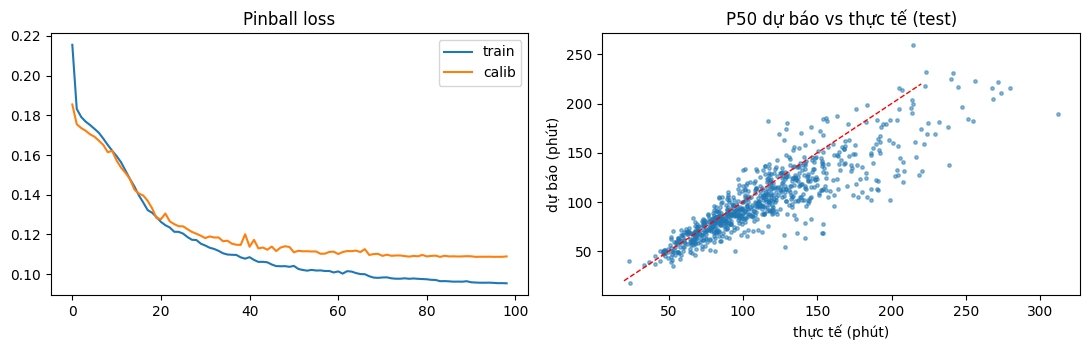

In [12]:
# (Tuỳ chọn) đồ thị
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot([h[0] for h in hist], label="train"); ax[0].plot([h[1] for h in hist], label="calib"); ax[0].set_title("Pinball loss"); ax[0].legend()
    s = np.random.default_rng(0).choice(len(yte), size=min(800, len(yte)), replace=False)
    ax[1].scatter(yte[s], pt[s, 0], s=6, alpha=.5); ax[1].plot([20, 220], [20, 220], "r--", lw=1); ax[1].set_title("P50 dự báo vs thực tế (test)")
    ax[1].set_xlabel("thực tế (phút)"); ax[1].set_ylabel("dự báo (phút)")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "eta_training.png"), dpi=110); plt.show()
except Exception as e:
    print("Bỏ qua đồ thị:", e)

## 5. Xuất ONNX và kiểm tra khớp
Backend nạp bằng `onnxruntime` (không cần PyTorch). Đầu vào `features` `float32 [N, 12]`, đầu ra `eta` `float32 [N, 2]`.

In [13]:
import onnx, onnxruntime as ort
ONNX_PATH = os.path.join(OUT_DIR, "eta_model.onnx")
model.eval()
dummy = torch.zeros(1, len(INPUT_ORDER), dtype=torch.float32)
kw = dict(input_names=["features"], output_names=["eta"], dynamic_axes={"features": {0: "N"}, "eta": {0: "N"}}, opset_version=17)
try:
    torch.onnx.export(model, dummy, ONNX_PATH, dynamo=False, **kw)   # bộ xuất cổ điển: ổn định, không cần onnxscript
except TypeError:
    torch.onnx.export(model, dummy, ONNX_PATH, **kw)                 # torch cũ chưa có tham số dynamo
onnx.checker.check_model(onnx.load(ONNX_PATH))

sess = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])
assert sess.get_inputs()[0].name == "features" and sess.get_outputs()[0].name == "eta"
po = sess.run(["eta"], {"features": Xte})[0]
diff = float(np.abs(po - pt).max())
print(f"ONNX vs PyTorch: lệch tối đa {diff:.2e} phút | P90 ≥ P50 ở mọi dòng: {bool((po[:,1] >= po[:,0]).all())}")
assert diff < 1e-2 and (po[:, 1] >= po[:, 0]).all()
one = sess.run(["eta"], {"features": Xte[:1]})[0]
print("Thử 1 dòng:", one.round(1).tolist(), "| thực tế:", float(yte[0]))

/tmp/ipykernel_50/659166723.py:7: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, ONNX_PATH, dynamo=False, **kw)   # bộ xuất cổ điển: ổn định, không cần onnxscript


ONNX vs PyTorch: lệch tối đa 6.10e-05 phút | P90 ≥ P50 ở mọi dòng: True
Thử 1 dòng: [[70.69999694824219, 83.30000305175781]] | thực tế: 82.80000305175781


In [14]:
# Model card (kèm mã băm để backend kiểm tra trước khi nạp)
onnx_sha = hashlib.sha256(open(ONNX_PATH, "rb").read()).hexdigest()
card = {
    "model_version": schema["model_version"],
    "model_file": "eta_model.onnx", "sha256": onnx_sha,
    "trained_on": {"file": "eta_trips.csv", "sha256": csv_sha, "rows": int(len(df)), "is_simulated": True},
    "framework": f"pytorch {torch.__version__} -> onnx opset 17",
    "architecture": f"MLP {len(INPUT_ORDER)}-{HIDDEN}-{HIDDEN}-2 (chuẩn hoá + hiệu chỉnh P90 nhúng trong model)",
    "feature_order": INPUT_ORDER, "input_dtype": "float32", "output_columns": ["p50_minutes", "p90_minutes"],
    "p90_offset_minutes": offset,
    "valid_ranges": schema["valid_ranges"],
    "metrics_test": {**{k: round(v, 4) for k, v in M.items()}, "improvement_vs_baseline_pct": imp, "strongest_baseline": best_name,
                     "improvement_vs_strongest_pct": round(imp_best, 2)},
    "baselines_test": {k: {m: round(x, 4) for m, x in v.items()} for k, v in BASE.items()},
    "promotion_gate": {"passed": promote, "min_mae_improvement_pct": schema["promotion_gate"]["min_mae_improvement_pct"], "p90_coverage_range": [lo, hi]},
    "notes": "Huấn luyện trên dữ liệu MÔ PHỎNG; chỉ chứng minh quy trình, không chứng minh độ chính xác ngoài đời.",
}
json.dump(card, open(os.path.join(OUT_DIR, "eta_model_card.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print(json.dumps(card["metrics_test"], ensure_ascii=False, indent=2))
print("\nFILE CẦN TẢI VỀ:")
for f in ("eta_model.onnx", "eta_model_card.json"):
    p = os.path.join(OUT_DIR, f); print(" •", p, f"({os.path.getsize(p)/1024:.1f} KB)")

{
  "mae_p50": 17.5388,
  "pinball_0.5": 8.7694,
  "pinball_0.9": 5.2337,
  "p90_coverage": 0.7653,
  "within15": 0.5899,
  "p90_abs_err": 39.8422,
  "improvement_vs_baseline_pct": {
    "rule_const_min": 53.5,
    "rule_dist_min": 51.9,
    "baseline_median_min": 33.6
  },
  "strongest_baseline": "baseline_median_min",
  "improvement_vs_strongest_pct": 33.65
}

FILE CẦN TẢI VỀ:
 • /kaggle/working/eta_model.onnx (22.7 KB)
 • /kaggle/working/eta_model_card.json (2.4 KB)


## Xong
Tải **`eta_model.onnx`** và **`eta_model_card.json`** (thư mục *Output* bên phải, hoặc `/kaggle/working/`) rồi gửi lại.
Nếu "CỔNG PROMOTE" báo *HẠ VỀ ETA LUẬT* vì độ phủ P90 — đó là do drift cố ý ở 2 tháng cuối, không phải lỗi; backend vẫn nhận model và tự quyết theo cổng.